# 15 · Carga de inferência e contrato de entrada

Este é um teste **operacional**, distinto de tolerância estatística a drift. O modelo congelado recebe lotes crescentes de `cs-test.csv`, que não possui rótulos. Medimos tempo de `DMatrix + predict`, tempo de `predict` após construir o lote, p50/p95 e vazão local. Em seguida verificamos se uma coluna ausente, tipo inválido ou ordem trocada é rejeitada. O corte de decisão continua 0,50; `scale_pos_weight=13.882494684620836` foi aplicado no treinamento do Booster carregado, não em uma nova chamada de ajuste.

**Fontes:** [Civo, stress testing ML models](https://www.civo.com/learn/stress-testing-machine-learning-models) motiva casos extremos, lotes crescentes, latência e erro; BoE SS1/23 §4.4 motiva monitoramento e critérios operacionais. O exemplo da Civo com `fit` e rótulos aleatórios **não** é um teste válido de inferência do classificador de crédito e não é reproduzido aqui.

**Reprodução:** hardware, concorrência, versão do XGBoost e aquecimento afetam os números. Eles são medições desta máquina e não SLA de produção. Defina orçamento de tempo e concorrência reais antes de converter estes resultados em limites operacionais.


In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 1. Preparação e validação do artefato

Usamos o mesmo hash e ordem das dez entradas declaradas no manifesto. Para o tamanho de lote $n$, vazão $V=n/t$ registros por segundo, em que $t$ é o tempo em segundos. p50 é a mediana de repetições; p95 é o percentil 95. `DMatrix + predict` aproxima o caminho completo nesta sessão, mas exclui leitura de rede, serialização de API e concorrência.


In [2]:
from pathlib import Path
import hashlib, json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from IPython.display import display

P = DATA_DIR_PROJECT
OUT = TABLES_DIR
DATA = DATA_DIR_PROJECT
manifesto = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding='utf-8'))
features = manifesto['features']
assert np.isclose(manifesto['params_fornecidos']['scale_pos_weight'],13.882494684620836)
assert manifesto['cutoff'] == .50
path = MODEL_DIR / 'model_class_retreinado.json'
assert hashlib.sha256(path.read_bytes()).hexdigest() == manifesto['model_sha256']
model = xgb.Booster(model_file=str(path))
data = pd.read_csv(DATA/'cs-test.csv').drop(columns=['Unnamed: 0'])
assert data['SeriousDlqin2yrs'].isna().all()
assert list(data[features].columns) == features
print('Python',platform.python_version(),'| XGBoost',xgb.__version__,
      '| linhas sem rótulo',len(data),'| árvores',model.num_boosted_rounds())

Python 3.12.10 | XGBoost 3.0.0 | linhas sem rótulo 101503 | árvores 103


## 2. Lotes crescentes: construção e predição separadas

Primeiro aquecemos a rota de inferência. Cada repetição usa o mesmo lote, portanto varia tempo de execução, não conteúdo. O cronômetro de `predict` termina depois que o vetor de scores foi materializado em NumPy. Os tamanhos abaixo cabem nos 101.503 registros originais, sem criar casos sintéticos. Cinco repetições permitem apenas uma estimativa grosseira de p95; aumente esse número para um estudo de SLA.


In [3]:
tamanhos = [128,1024,8192,32768,100000]
repeticoes = 5
_ = model.predict(xgb.DMatrix(data[features].head(128),feature_names=features,
                               enable_categorical=True))
linhas = []
for n in tamanhos:
    lote = data[features].head(n).copy()
    tempos_total=[]; tempos_predict=[]; scores=None
    for rep in range(repeticoes):
        t0=time.perf_counter()
        dm=xgb.DMatrix(lote,feature_names=features,enable_categorical=True)
        t1=time.perf_counter()
        scores=model.predict(dm)
        t2=time.perf_counter()
        tempos_total.append(t2-t0)
        tempos_predict.append(t2-t1)
    linha={'n':n,'repeticoes':repeticoes,
           'total_p50_ms':1000*np.median(tempos_total),
           'total_p95_ms':1000*np.quantile(tempos_total,.95),
           'predict_p50_ms':1000*np.median(tempos_predict),
           'predict_p95_ms':1000*np.quantile(tempos_predict,.95),
           'vazao_total_p50_registros_s':n/np.median(tempos_total),
           'score_medio':float(np.mean(scores)),
           'fracao_score_ge_0_50':float(np.mean(scores>=.50))}
    linhas.append(linha)
res=pd.DataFrame(linhas)
res.to_csv(OUT/'resultados_carga_inferencia.csv',index=False)
display(res.round(3))

,n,repeticoes,total_p50_ms,total_p95_ms,predict_p50_ms,predict_p95_ms,vazao_total_p50_registros_s,score_medio,fracao_score_ge_0_50
0,128,5,1.332,1.454,0.291,0.461,96117.744,0.320,0.227
1,1024,5,1.452,1.793,0.503,0.578,705282.735,0.312,0.225
2,8192,5,2.844,4.090,1.521,2.491,2880146.267,0.325,0.247
3,32768,5,8.198,9.209,5.583,6.851,3996974.947,0.323,0.244
4,100000,5,29.165,33.479,22.261,26.730,3428814.383,0.322,0.242


## 3. Gráficos e interpretação

**Esquerda:** p50/p95 do tempo completo, em milissegundos, conforme o lote cresce. **Direita:** vazão calculada pela mediana do tempo completo. As curvas de latência incluem construção do `DMatrix`; elas não caracterizam uma API nem execução concorrente. A fração acima de 0,50 é **taxa de decisão**, não recall nem acurácia, porque `cs-test` não tem rótulos.


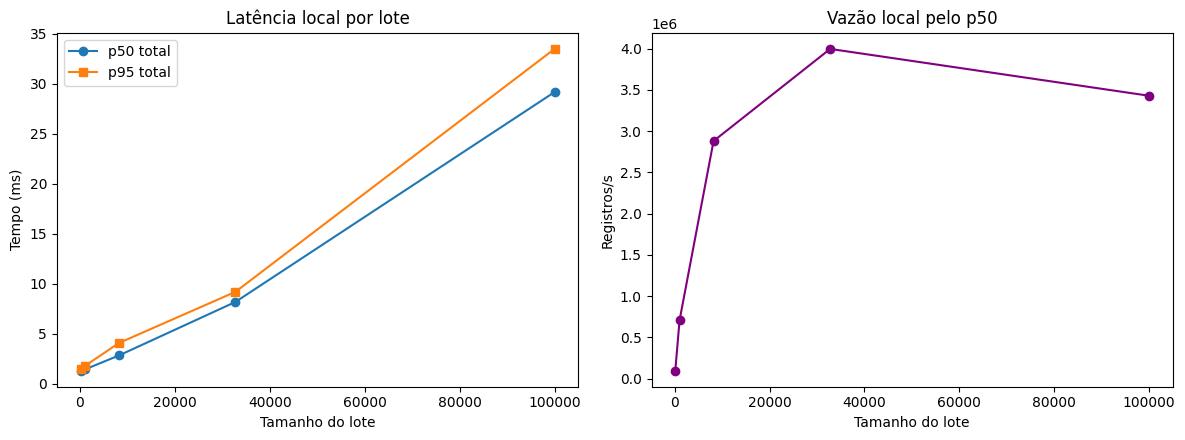

In [4]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].plot(res.n,res.total_p50_ms,marker='o',label='p50 total')
axs[0].plot(res.n,res.total_p95_ms,marker='s',label='p95 total')
axs[0].set(xlabel='Tamanho do lote',ylabel='Tempo (ms)',title='Latência local por lote')
axs[0].legend()
axs[1].plot(res.n,res.vazao_total_p50_registros_s,marker='o',color='purple')
axs[1].set(xlabel='Tamanho do lote',ylabel='Registros/s',title='Vazão local pelo p50')
fig.tight_layout(); fig.savefig(FIGURES_DIR / 'grafico_carga_inferencia.png',dpi=160,bbox_inches='tight')
plt.show()

## 4. Contrato de esquema: coluna, ordem e tipo

O contrato exige as dez colunas com nomes e ordem do treinamento e valores numéricos ou ausentes aceitos pelo XGBoost. A seguir capturamos falhas sem interromper a execução; isso documenta o comportamento **desta versão da biblioteca**. `NaN` é um valor previsto pela política de faltantes do modelo e não deve ser confundido com coluna omitida. Se um sistema inserir uma coluna ausente por padrão, precisa monitorar e registrar essa decisão de engenharia.


In [5]:
amostra=data[features].head(100).copy()
casos={
    'contrato_correto':amostra,
    'coluna_ausente':amostra.drop(columns=[features[0]]),
    'ordem_trocada':amostra[features[::-1]],
    'texto_invalido':amostra.assign(**{features[0]:['invalido']*len(amostra)}),
    'NaN_em_uma_coluna':amostra.assign(**{features[0]:np.nan}),
}
checagens=[]
for nome,quadro in casos.items():
    try:
        dm=xgb.DMatrix(quadro,feature_names=list(quadro.columns),enable_categorical=True)
        sc=model.predict(dm,validate_features=True)
        checagens.append({'caso':nome,'resultado':'aceito','detalhe':f'{len(sc)} scores'})
    except Exception as exc:
        checagens.append({'caso':nome,'resultado':'rejeitado',
                          'detalhe':str(exc).splitlines()[0][:180]})
contrato=pd.DataFrame(checagens)
contrato.to_csv(OUT/'resultados_contrato_inferencia.csv',index=False)
display(contrato)
assert contrato.loc[contrato.caso=='contrato_correto','resultado'].iloc[0]=='aceito'

,caso,resultado,detalhe
0,contrato_correto,aceito,100 scores
1,coluna_ausente,rejeitado,feature_names mismatch: ['RevolvingUtilization...
2,ordem_trocada,rejeitado,feature_names mismatch: ['RevolvingUtilization...
3,texto_invalido,rejeitado,"DataFrame.dtypes for data must be int, float, ..."
4,NaN_em_uma_coluna,aceito,100 scores


## 5. Aplicação em outro contexto

1. Congelar artefato, versão das bibliotecas, esquema, política de ausentes e cutoff.
2. Aquecer e medir a mesma rota de inferência usada em produção com lotes e concorrência reais; coletar p50, p95, vazão, memória e erros de timeout em janelas repetidas.
3. Incluir casos extremos **dentro e fora** do suporte aceito, com política explícita de rejeição ou revisão humana.
4. Comparar com um SLA de negócio definido antes do teste. Este caderno não define esse SLA.
5. Manter monitoramento estatístico (PSI/score/desempenho quando há rótulos) separado de monitoramento operacional (latência/erros), mas versionado junto ao mesmo Booster.
